# 05 – Customer Segmentation: K-Means and Hierarchical Clustering

## Notebook purpose

This notebook develops and compares unsupervised customer-segmentation solutions using the customer-level features prepared in Notebook 04.

The analysis begins with **RFM (Recency, Frequency and Monetary) K-Means** as the baseline. It then examines the effect of scaling choice, tests an extended feature set, evaluates a reduced extended feature set, and begins the comparison with Ward-linkage Agglomerative Hierarchical Clustering.

## Modelling principles

- `CustomerID` is used only to identify and match customers; it is not a clustering feature.
- Cluster profiles are interpreted using the original, unscaled customer-level variables.
- Candidate cluster counts are assessed using internal validation metrics and the interpretability of the resulting profiles.
- Inertia values are interpreted only within the same feature space and scaling method; they should not be compared directly across differently scaled datasets.
- Cluster labels are arbitrary identifiers, not customer rankings or target classes.
- The analysis is exploratory and does not establish causal relationships.

**Input:** processed customer-level feature datasets created in Notebook 04.  
**Output:** candidate cluster assignments, evaluation metrics and descriptive cluster profiles for subsequent model comparison.


In [29]:

# Section 5.1 – Import libraries and load baseline modelling data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Identify project root
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Load original RFM StandardScaler dataset
scaled_rfm = pd.read_csv(
    PROCESSED_DIR / "original_rfm_standard_scaled.csv"
)

# Load original customer-level features for later interpretation
customer_features = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)

# Separate identifiers and clustering features
customer_ids = scaled_rfm["CustomerID"].copy()

X_rfm = scaled_rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Customer-level profiling dataset
rfm_profile_df = customer_features[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
].copy()

print("K-MEANS BASELINE DATASET")
print("-----------------------")

print("Scaled RFM shape:", X_rfm.shape)
print("Customer count:", customer_ids.nunique())
print("Feature columns:", X_rfm.columns.tolist())

print("\nMissing values:")
print(X_rfm.isna().sum())

print("\nInfinite values:", np.isinf(X_rfm.to_numpy()).sum())
print("Duplicate Customer IDs:", customer_ids.duplicated().sum())

print("\nCustomer profiling dataset:", rfm_profile_df.shape)


K-MEANS BASELINE DATASET
-----------------------
Scaled RFM shape: (4335, 3)
Customer count: 4335
Feature columns: ['Recency', 'Frequency', 'Monetary']

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Infinite values: 0
Duplicate Customer IDs: 0

Customer profiling dataset: (4335, 4)


**Data check.** The modelling input contains 4,335 unique customers and three standardized RFM features. There are no missing or infinite feature values, and CustomerID is unique. The separate customer-level profile table retains the original RFM values for interpretation.

### Section 5.2 – Determine the optimal number of clusters

In [30]:

# Section 5.2 – Evaluate candidate cluster counts

k_values = range(2, 11)

kmeans_results = []

for k in k_values:

    print(f"Evaluating K = {k}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_rfm)

    # Calculate clustering evaluation metrics
    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_rfm, labels)
    db_index = davies_bouldin_score(X_rfm, labels)
    ch_index = calinski_harabasz_score(X_rfm, labels)

    kmeans_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette_Score": silhouette,
        "Davies_Bouldin_Index": db_index,
        "Calinski_Harabasz_Index": ch_index
    })

# Create results table
kmeans_results_df = pd.DataFrame(kmeans_results)

print("\nK-MEANS CLUSTER EVALUATION RESULTS")
display(kmeans_results_df.round(4))


Evaluating K = 2
Evaluating K = 3
Evaluating K = 4
Evaluating K = 5
Evaluating K = 6
Evaluating K = 7
Evaluating K = 8
Evaluating K = 9
Evaluating K = 10

K-MEANS CLUSTER EVALUATION RESULTS


,K,Inertia,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,2,6871.5452,0.4062,0.9167,3867.5882
1,3,4304.1872,0.4151,0.8269,4378.5206
2,4,3244.1459,0.3799,0.8588,4343.6473
3,5,2761.7164,0.3441,0.9394,4015.0423
4,6,2393.9056,0.3319,0.9791,3837.7128
5,7,2164.6116,0.3014,1.0172,3612.4812
6,8,1960.9045,0.3002,1.0016,3481.4836
7,9,1817.2331,0.2833,1.0344,3329.1764
8,10,1688.2561,0.2821,1.0249,3221.3021


**Interpretation.** Among K = 2–10, K = 3 has the highest Silhouette Score (0.4151), the lowest Davies–Bouldin Index (0.8269), and the highest Calinski–Harabasz Index (4,378.5206). The Elbow curve should be considered alongside these metrics rather than used as a stand-alone rule. K = 3 is therefore selected as the provisional RFM solution for profiling, not yet as the final project model.


### Section 5.3 – Visualise the evaluation metrics

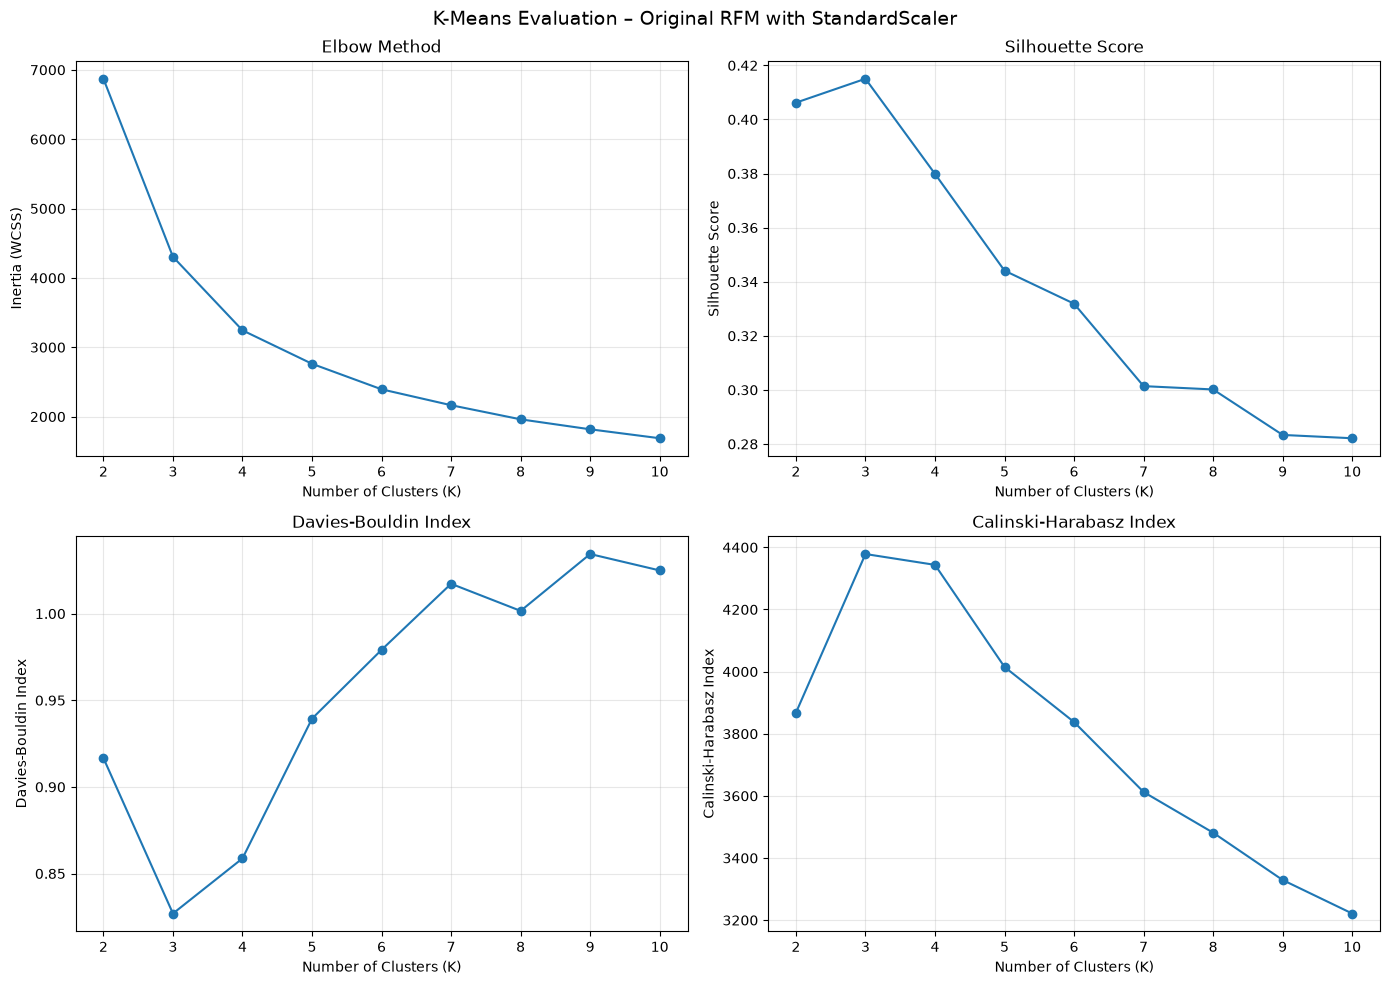

In [31]:

# Section 5.3 – Visualise cluster evaluation metrics

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow Method
axes[0, 0].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Inertia"],
    marker="o"
)
axes[0, 0].set_title("Elbow Method")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Inertia (WCSS)")
axes[0, 0].set_xticks(list(k_values))
axes[0, 0].grid(alpha=0.3)

# Silhouette Score
axes[0, 1].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Silhouette_Score"],
    marker="o"
)
axes[0, 1].set_title("Silhouette Score")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].set_xticks(list(k_values))
axes[0, 1].grid(alpha=0.3)

# Davies-Bouldin Index
axes[1, 0].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Davies_Bouldin_Index"],
    marker="o"
)
axes[1, 0].set_title("Davies-Bouldin Index")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("Davies-Bouldin Index")
axes[1, 0].set_xticks(list(k_values))
axes[1, 0].grid(alpha=0.3)

# Calinski-Harabasz Index
axes[1, 1].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Calinski_Harabasz_Index"],
    marker="o"
)
axes[1, 1].set_title("Calinski-Harabasz Index")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("Calinski-Harabasz Index")
axes[1, 1].set_xticks(list(k_values))
axes[1, 1].grid(alpha=0.3)

plt.suptitle(
    "K-Means Evaluation – Original RFM with StandardScaler",
    fontsize=14
)
plt.tight_layout()
plt.show()


**Interpretation.** The metric plots provide a visual cross-check of the evaluation table. The strongest overall internal-validation results occur at K = 3. Inertia decreases as K increases, as expected, so its curve is used to assess diminishing returns rather than to identify a unique optimum mechanically.

### Section 5.4 – Fit the provisional K = 3 model

In [32]:

# Section 5.4 – Fit K-Means with 3 clusters

kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

# Generate cluster labels
cluster_labels = kmeans_3.fit_predict(X_rfm)

# Map cluster labels to CustomerID
cluster_assignments = pd.DataFrame({
    "CustomerID": customer_ids,
    "Cluster": cluster_labels
})

# Merge with original, unscaled RFM features
clustered_customers = rfm_profile_df.merge(
    cluster_assignments,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

# Calculate cluster sizes
cluster_sizes = (
    clustered_customers["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_sizes.columns = ["Cluster", "Customer_Count"]
cluster_sizes["Percentage"] = (
    cluster_sizes["Customer_Count"]
    / len(clustered_customers) * 100
)

print("K-MEANS CLUSTER DISTRIBUTION")
display(cluster_sizes.round(2))

print("\nTotal customers assigned:", len(clustered_customers))
print("Unassigned customers:", clustered_customers["Cluster"].isna().sum())


K-MEANS CLUSTER DISTRIBUTION


,Cluster,Customer_Count,Percentage
0,0,2025,46.71
1,1,1325,30.57
2,2,985,22.72



Total customers assigned: 4335
Unassigned customers: 0


**Interpretation.** The provisional K = 3 solution assigns all 4,335 customers. The three clusters contain 2,025 (46.71%), 1,325 (30.57%) and 985 (22.72%) customers. No customers are left unassigned.

### Section 5.5 – Profile the three clusters

In [33]:

# Section 5.5 – Customer cluster profiling

cluster_profile_mean = (
    clustered_customers
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .mean()
    .round(2)
)

cluster_profile_median = (
    clustered_customers
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)

print("CLUSTER PROFILE – MEAN VALUES")
display(cluster_profile_mean)

print("\nCLUSTER PROFILE – MEDIAN VALUES")
display(cluster_profile_median)


CLUSTER PROFILE – MEAN VALUES


,Recency,Frequency,Monetary
Cluster,,,
0,55.23,2.03,604.45
1,30.54,9.76,5374.77
2,255.70,1.39,404.57



CLUSTER PROFILE – MEDIAN VALUES


,Recency,Frequency,Monetary
Cluster,,,
0,46.0,2.0,501.28
1,18.0,7.0,2504.13
2,253.0,1.0,290.34


**Interpretation.** Median profiles suggest three behaviourally distinct groups: Cluster 0 is relatively active but purchases infrequently and spends moderately; Cluster 1 is the most recently active, most frequent and highest-spending group; Cluster 2 has the longest time since its last purchase and the lowest frequency and median monetary value. These patterns support provisional labels such as occasional active, high-value active and inactive/lapsed. The labels describe observed behaviour, not fixed customer identities.

### Section 5.6 – RFM distribution by cluster

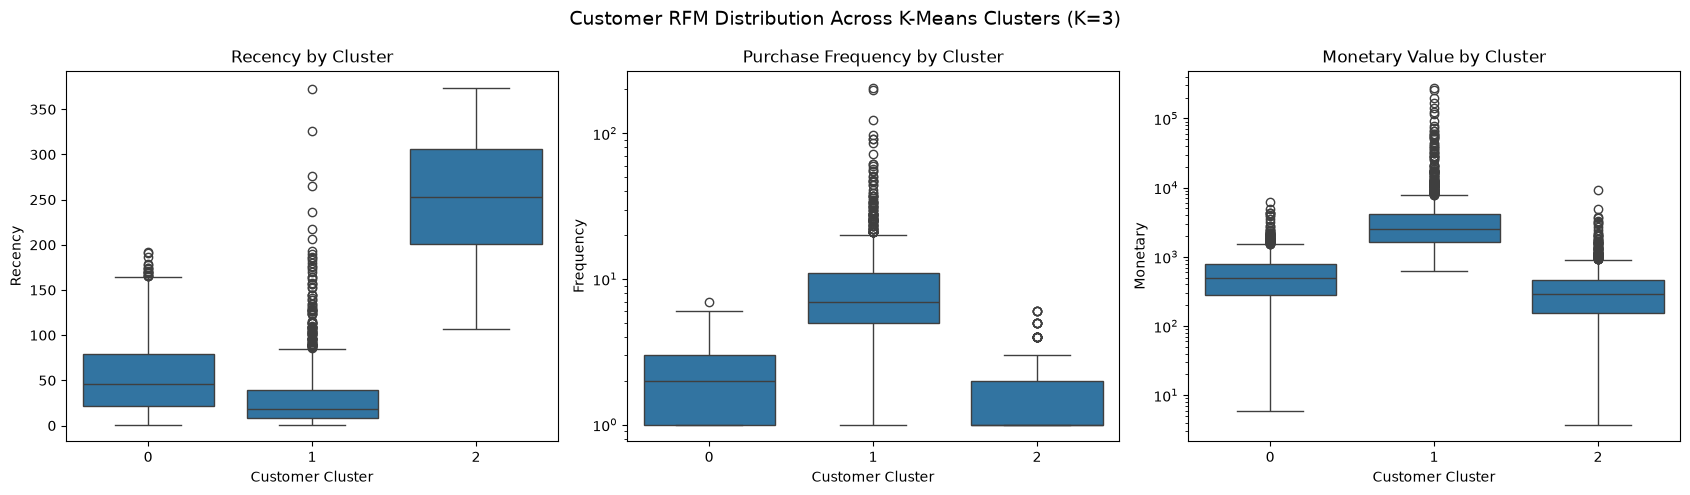

In [34]:

# Section 5.6 – Visualise RFM distributions by cluster

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

features = ["Recency", "Frequency", "Monetary"]
titles = [
    "Recency by Cluster",
    "Purchase Frequency by Cluster",
    "Monetary Value by Cluster"
]

for ax, feature, title in zip(axes, features, titles):

    sns.boxplot(
        data=clustered_customers,
        x="Cluster",
        y=feature,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Customer Cluster")
    ax.set_ylabel(feature)

    # Log scale helps display skewed Frequency and Monetary values
    if feature in ["Frequency", "Monetary"]:
        ax.set_yscale("log")

plt.suptitle(
    "Customer RFM Distribution Across K-Means Clusters (K=3)",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Interpretation.** The boxplots provide a distribution-level view of the RFM differences. Frequency and Monetary are displayed on logarithmic axes because of their skewed distributions. The plots should be read together with the median profiles, since means and extreme values can be influenced by a small number of high-activity customers.

### Section 5.7 – Repeated initialisation stability check

In [35]:

# Section 5.7 – K-Means stability across random seeds

stability_results = []

random_seeds = [0, 10, 21, 42, 50, 100, 123, 2025, 2026, 2027]

for seed in random_seeds:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=20
    )

    labels = model.fit_predict(X_rfm)

    stability_results.append({
        "Random_Seed": seed,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(X_rfm, labels),
        "Davies_Bouldin_Index": davies_bouldin_score(X_rfm, labels),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_rfm, labels)
    })

stability_df = pd.DataFrame(stability_results)

print("K-MEANS STABILITY RESULTS")
display(stability_df.round(4))

print("\nMETRIC VARIABILITY")
display(
    stability_df.drop(columns="Random_Seed")
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


K-MEANS STABILITY RESULTS


,Random_Seed,Inertia,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,0,4304.2025,0.4151,0.8269,4378.5206
1,10,4304.1967,0.4151,0.8268,4378.5157
2,21,4304.2078,0.4151,0.8269,4378.4970
3,42,4304.1872,0.4151,0.8269,4378.5206
4,50,4304.1796,0.4151,0.8269,4378.5318
5,100,4304.2078,0.4151,0.8269,4378.4970
6,123,4304.1762,0.4151,0.8269,4378.5371
7,2025,4304.1746,0.4151,0.8269,4378.5371
8,2026,4304.1762,0.4151,0.8269,4378.5371
9,2027,4304.1746,0.4151,0.8269,4378.5371



METRIC VARIABILITY


,Inertia,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
mean,4304.1883,0.4151,0.8269,4378.5231
std,0.0140,0.0000,0.0000,0.0159
min,4304.1746,0.4151,0.8268,4378.4970
max,4304.2078,0.4151,0.8269,4378.5371


**Interpretation.** Across ten random seeds, the K = 3 metrics vary very little (inertia mean 4,304.1883; standard deviation 0.0140; Silhouette Score 0.4151 throughout to four decimal places). This indicates that the selected K-Means configuration is highly stable to the tested initialisations when `n_init=20` is used.

### Section 5.8 – Compare StandardScaler and RobustScaler

In [36]:

# Section 5.8 – Compare StandardScaler and RobustScaler

# Load RobustScaler RFM dataset
scaled_rfm_robust = pd.read_csv(
    PROCESSED_DIR / "original_rfm_robust_scaled.csv"
)

X_rfm_robust = scaled_rfm_robust[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Fit K-Means using RobustScaler
kmeans_robust = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

robust_labels = kmeans_robust.fit_predict(X_rfm_robust)

# Calculate evaluation metrics
scaler_comparison = pd.DataFrame([
    {
        "Scaler": "StandardScaler",
        "Inertia": kmeans_3.inertia_,
        "Silhouette": silhouette_score(X_rfm, cluster_labels),
        "Davies_Bouldin": davies_bouldin_score(X_rfm, cluster_labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_rfm, cluster_labels)
    },
    {
        "Scaler": "RobustScaler",
        "Inertia": kmeans_robust.inertia_,
        "Silhouette": silhouette_score(X_rfm_robust, robust_labels),
        "Davies_Bouldin": davies_bouldin_score(X_rfm_robust, robust_labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_rfm_robust, robust_labels)
    }
])

print("SCALING METHOD COMPARISON – RFM, K=3")
display(scaler_comparison.round(4))

# Compare cluster sizes
standard_distribution = pd.Series(cluster_labels).value_counts().sort_index()
robust_distribution = pd.Series(robust_labels).value_counts().sort_index()

distribution_comparison = pd.DataFrame({
    "StandardScaler": standard_distribution,
    "RobustScaler": robust_distribution
}).fillna(0).astype(int)

print("\nCLUSTER SIZE COMPARISON")
display(distribution_comparison)


SCALING METHOD COMPARISON – RFM, K=3


,Scaler,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,StandardScaler,4304.1872,0.4151,0.8269,4378.5206
1,RobustScaler,2217.7682,0.4210,0.8079,4558.4739



CLUSTER SIZE COMPARISON


,StandardScaler,RobustScaler
0,2025,1987
1,1325,1361
2,985,987


**Interpretation.** RobustScaler produces slightly stronger internal metrics in its own scaled feature space (Silhouette 0.4210; Davies–Bouldin 0.8079; Calinski–Harabasz 4,558.4739) than StandardScaler. Inertia values are not directly comparable across the two scaling spaces. StandardScaler remains the designated baseline to preserve the original modelling plan; RobustScaler is treated as a sensitivity comparison.

### Section 5.9 – Compare cluster assignments

In [37]:

# Section 5.9 – Compare StandardScaler and RobustScaler assignments

from sklearn.metrics import adjusted_rand_score

# StandardScaler assignments
standard_assignments = pd.DataFrame({
    "CustomerID": customer_ids,
    "Standard_Cluster": cluster_labels
})

# RobustScaler assignments
robust_customer_ids = scaled_rfm_robust["CustomerID"]

robust_assignments = pd.DataFrame({
    "CustomerID": robust_customer_ids,
    "Robust_Cluster": robust_labels
})

# Match assignments using CustomerID
assignment_comparison = standard_assignments.merge(
    robust_assignments,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

# Calculate Adjusted Rand Index
ari_score = adjusted_rand_score(
    assignment_comparison["Standard_Cluster"],
    assignment_comparison["Robust_Cluster"]
)

print("CUSTOMER ASSIGNMENT AGREEMENT")
print("Customers compared:", len(assignment_comparison))
print("Adjusted Rand Index:", round(ari_score, 4))

# Cross-tabulation of cluster assignments
cluster_cross_tab = pd.crosstab(
    assignment_comparison["Standard_Cluster"],
    assignment_comparison["Robust_Cluster"],
    margins=True
)

print("\nCLUSTER ASSIGNMENT CROSS-TABULATION")
display(cluster_cross_tab)


CUSTOMER ASSIGNMENT AGREEMENT
Customers compared: 4335
Adjusted Rand Index: 0.9488

CLUSTER ASSIGNMENT CROSS-TABULATION


Robust_Cluster,0,1,2,All
Standard_Cluster,,,,
0,1972,42,11,2025
1,6,1318,1,1325
2,9,1,975,985
All,1987,1361,987,4335


**Interpretation.** The Adjusted Rand Index (ARI) of 0.9488 indicates very strong agreement between the StandardScaler and RobustScaler customer partitions. The cross-tabulation shows that most customers retain corresponding cluster assignments, although cluster IDs themselves are arbitrary and should not be matched by their numeric labels alone.

### Section 5.10 – Compare RFM profiles across scaling methods

In [38]:

# Section 5.10 – Compare RFM profiles across scaling methods

# StandardScaler cluster profiles
standard_profile = (
    clustered_customers
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
)

# RobustScaler customer assignments
robust_clustered = rfm_profile_df.merge(
    robust_assignments,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

robust_profile = (
    robust_clustered
    .groupby("Robust_Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
)

# Display profiles separately
print("STANDARD SCALER – MEDIAN RFM PROFILE")
display(standard_profile.round(2))

print("\nROBUST SCALER – MEDIAN RFM PROFILE")
display(robust_profile.round(2))


STANDARD SCALER – MEDIAN RFM PROFILE


,Recency,Frequency,Monetary
Cluster,,,
0,46.0,2.0,501.28
1,18.0,7.0,2504.13
2,253.0,1.0,290.34



ROBUST SCALER – MEDIAN RFM PROFILE


,Recency,Frequency,Monetary
Robust_Cluster,,,
0,46.0,2.0,487.99
1,18.0,7.0,2479.16
2,253.0,1.0,292.47


**Interpretation.** The median RFM profiles are very similar across the two scaling approaches. This supports the conclusion that the broad customer-segment structure is not materially changed by the choice between StandardScaler and RobustScaler in this experiment.

### Section 5.11 – Load the Extended feature dataset

In [39]:

# Section 5.11 – Load Extended feature dataset

scaled_extended = pd.read_csv(
    PROCESSED_DIR / "original_extended_standard_scaled.csv"
)

X_extended = scaled_extended[
    [
        "Recency",
        "Frequency",
        "Monetary",
        "AverageOrderValue",
        "TotalQuantity",
        "ProductDiversity"
    ]
].copy()

extended_customer_ids = scaled_extended["CustomerID"].copy()

print("EXTENDED FEATURE DATASET")
print("------------------------")
print("Dataset shape:", X_extended.shape)
print("Customer count:", extended_customer_ids.nunique())
print("Features:", X_extended.columns.tolist())

print("\nMissing values:")
print(X_extended.isna().sum())

print("\nInfinite values:",
      np.isinf(X_extended.to_numpy()).sum())


EXTENDED FEATURE DATASET
------------------------
Dataset shape: (4335, 6)
Customer count: 4335
Features: ['Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'TotalQuantity', 'ProductDiversity']

Missing values:
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
TotalQuantity        0
ProductDiversity     0
dtype: int64

Infinite values: 0


**Data check.** The extended modelling input contains six standardized features for the same 4,335 customers. All six features are free of missing and infinite values. CustomerID remains separate from the feature matrix.

### Section 5.12 – Evaluate K-Means on Extended features

In [40]:

# Section 5.12 – Evaluate K-Means on Extended features

extended_results = []

for k in range(2, 11):

    print(f"Evaluating K = {k}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_extended)

    extended_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(X_extended, labels),
        "Davies_Bouldin_Index": davies_bouldin_score(X_extended, labels),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_extended, labels)
    })

extended_results_df = pd.DataFrame(extended_results)

print("\nEXTENDED K-MEANS EVALUATION RESULTS")
display(extended_results_df.round(4))


Evaluating K = 2
Evaluating K = 3
Evaluating K = 4
Evaluating K = 5
Evaluating K = 6
Evaluating K = 7
Evaluating K = 8
Evaluating K = 9
Evaluating K = 10

EXTENDED K-MEANS EVALUATION RESULTS


,K,Inertia,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,2,15128.1309,0.3511,1.0616,3116.7941
1,3,11958.7310,0.2724,1.2329,2545.0116
2,4,10322.0384,0.2592,1.2351,2194.1667
3,5,9123.2417,0.2422,1.1941,2003.6786
4,6,8172.0931,0.2468,1.1955,1889.8595
5,7,7498.6904,0.2302,1.2091,1780.6876
6,8,7011.5645,0.2171,1.2277,1674.9119
7,9,6607.2163,0.2222,1.2244,1587.9880
8,10,6264.5407,0.2185,1.2300,1514.6867


**Interpretation.** For the extended feature set, K = 2 gives the highest Silhouette Score (0.3511), the lowest Davies–Bouldin Index (1.0616), and the highest Calinski–Harabasz Index (3,116.7941) among the tested values. The results therefore favour a two-cluster solution for this feature space.

### Section 5.13 – Visualise the evaluation metrics

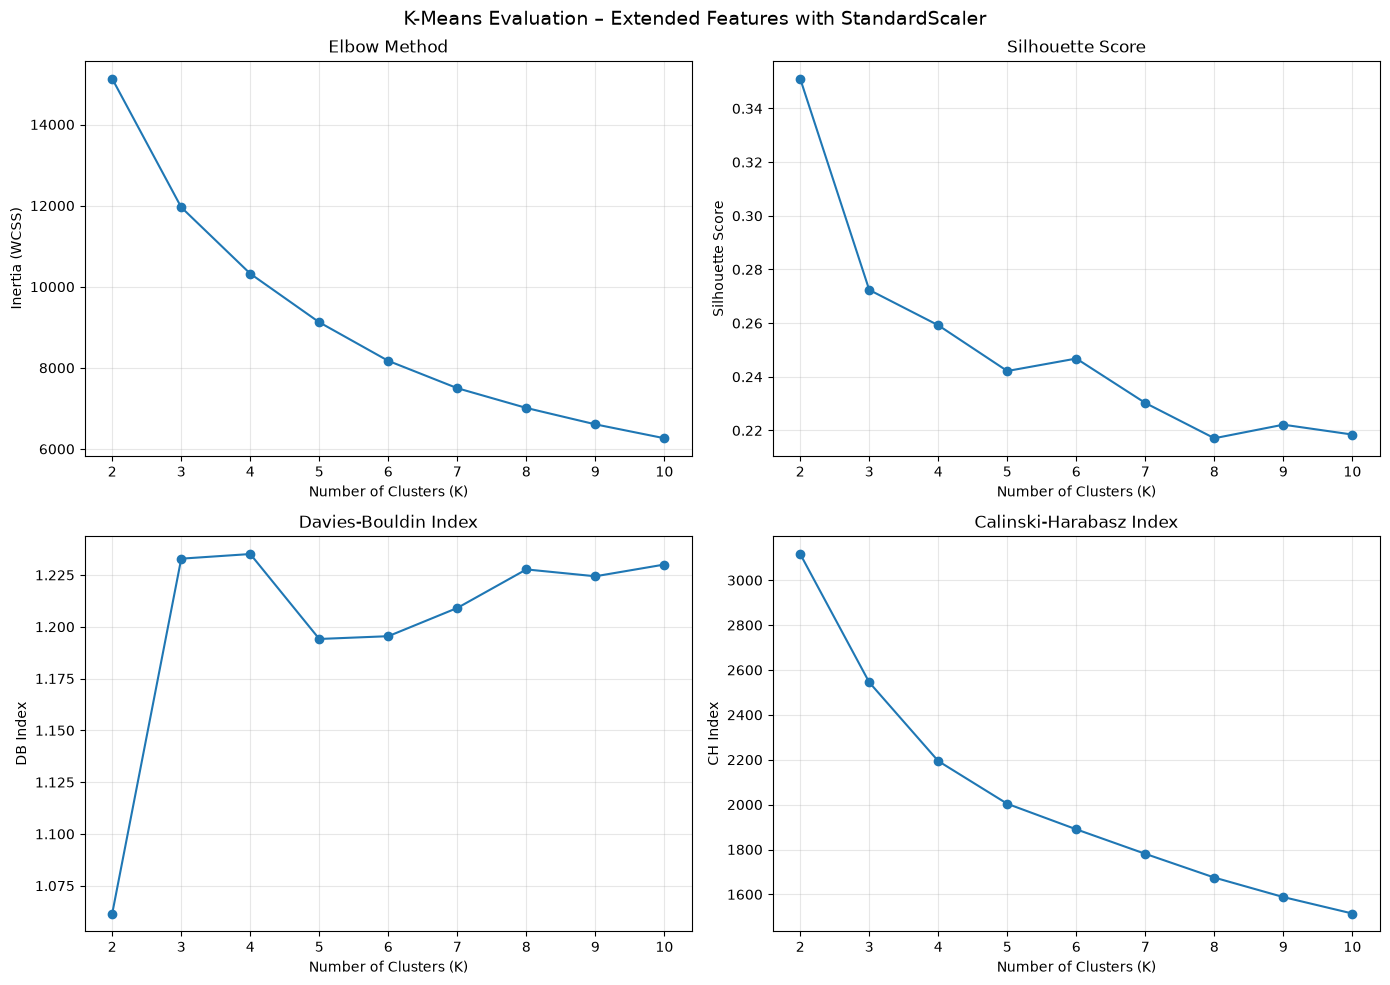

In [41]:

# Section 5.13 – Visualise Extended K-Means metrics

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = [
    ("Inertia", "Elbow Method", "Inertia (WCSS)"),
    ("Silhouette_Score", "Silhouette Score", "Silhouette Score"),
    ("Davies_Bouldin_Index", "Davies-Bouldin Index", "DB Index"),
    ("Calinski_Harabasz_Index", "Calinski-Harabasz Index", "CH Index")
]

for ax, (column, title, ylabel) in zip(axes.flat, metrics):

    ax.plot(
        extended_results_df["K"],
        extended_results_df[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(2, 11))
    ax.grid(alpha=0.3)

plt.suptitle(
    "K-Means Evaluation – Extended Features with StandardScaler",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Interpretation.** The metric plots reinforce the evaluation table: the internal-validation measures are strongest at K = 2, while inertia declines progressively as more clusters are added. K = 2 is carried forward for extended-feature profiling.

### Section 5.14 Fit Extended K-Means with K = 2


In [42]:
# Fit Extended K-Means with K = 2

extended_kmeans_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

extended_labels_k2 = extended_kmeans_k2.fit_predict(X_extended)

# Load original customer-level features
extended_profile_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "original_customer_features.csv"
)

# Attach cluster labels
extended_profile_df["Cluster"] = extended_labels_k2

# Check cluster sizes
extended_cluster_sizes = (
    extended_profile_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("EXTENDED K-MEANS CLUSTER DISTRIBUTION (K=2)")
display(
    extended_cluster_sizes.to_frame(name="Customer_Count")
)

print("Cluster percentages:")
display(
    (extended_cluster_sizes / len(extended_profile_df) * 100)
    .round(2)
    .to_frame(name="Percentage")
)

EXTENDED K-MEANS CLUSTER DISTRIBUTION (K=2)


,Customer_Count
Cluster,
0,2271
1,2064


Cluster percentages:


,Percentage
Cluster,
0,52.39
1,47.61


**Interpretation.** The extended K-Means K = 2 solution divides the 4,335 customers into 2,271 (52.39%) and 2,064 (47.61%) customers, producing two similarly sized groups.

In [43]:
# Extended K-Means: Cluster Profiling

extended_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "ProductDiversity"
]

# Calculate mean values
extended_cluster_means = (
    extended_profile_df
    .groupby("Cluster")[extended_features]
    .mean()
    .round(2)
)

# Calculate median values
extended_cluster_medians = (
    extended_profile_df
    .groupby("Cluster")[extended_features]
    .median()
    .round(2)
)

print("EXTENDED K-MEANS: CLUSTER MEAN PROFILES")
display(extended_cluster_means)

print("EXTENDED K-MEANS: CLUSTER MEDIAN PROFILES")
display(extended_cluster_medians)

EXTENDED K-MEANS: CLUSTER MEAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,,,,
0,139.86,1.59,355.30,249.44,208.55,22.36
1,41.92,7.17,3845.54,598.16,2261.78,104.40


EXTENDED K-MEANS: CLUSTER MEDIAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,,,,
0,107.0,1.0,311.65,204.18,167.0,18.0
1,24.0,5.0,1706.18,371.20,1022.5,78.0


**Interpretation.** Cluster 1 has lower median Recency (24 days), higher Frequency (5 invoices), higher Monetary value (£1,706.18), higher Average Order Value (£371.20), greater Total Quantity (1,022.5) and greater Product Diversity (78). Cluster 0 has comparatively lower engagement and spending. The extended solution therefore separates a more engaged, higher-value group from a less engaged, lower-value group. Medians are particularly useful here because the feature distributions are skewed.

In [44]:
# Load reduced extended features (StandardScaler)

reduced_extended_scaled = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" /
    "original_reduced_extended_standard_scaled.csv"
)

# Keep only the five modelling features
reduced_extended_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "ProductDiversity"
]

X_reduced_extended = reduced_extended_scaled[
    reduced_extended_features
].copy()

print("REDUCED EXTENDED FEATURE DATASET")
print("Dataset shape:", X_reduced_extended.shape)
print("Features:", list(X_reduced_extended.columns))

print("\nMissing values:")
display(X_reduced_extended.isnull().sum())

print("\nInfinite values:")
display(
    pd.Series(
        np.isinf(X_reduced_extended).sum(),
        index=X_reduced_extended.columns
    )
)

print("\nCustomer count:", len(X_reduced_extended))

REDUCED EXTENDED FEATURE DATASET
Dataset shape: (4335, 5)
Features: ['Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'ProductDiversity']

Missing values:


Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
ProductDiversity     0
dtype: int64


Infinite values:


Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
ProductDiversity     0
dtype: int64


Customer count: 4335


**Data check.** The reduced extended feature set contains five standardized variables, excluding TotalQuantity while retaining the same 4,335 customers. No missing or infinite values are present.

### Section 5.15 – Reduced Extended K-Means evaluation (K = 2–10)

In [45]:
# Evaluate Reduced Extended K-Means for K = 2 to 10

reduced_extended_results = []

for k in range(2, 11):
    print(f"Evaluating K = {k}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_reduced_extended)

    reduced_extended_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(
            X_reduced_extended, labels
        ),
        "Davies_Bouldin_Index": davies_bouldin_score(
            X_reduced_extended, labels
        ),
        "Calinski_Harabasz_Index": calinski_harabasz_score(
            X_reduced_extended, labels
        )
    })

reduced_extended_results_df = pd.DataFrame(
    reduced_extended_results
)

print("\nREDUCED EXTENDED K-MEANS EVALUATION RESULTS")
display(reduced_extended_results_df.round(4))

Evaluating K = 2
Evaluating K = 3
Evaluating K = 4
Evaluating K = 5
Evaluating K = 6
Evaluating K = 7
Evaluating K = 8
Evaluating K = 9
Evaluating K = 10

REDUCED EXTENDED K-MEANS EVALUATION RESULTS


,K,Inertia,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,2,13161.8938,0.3360,1.1176,2802.5822
1,3,10504.1079,0.2726,1.2587,2303.5222
2,4,8871.2458,0.2643,1.1861,2083.6278
3,5,7824.9514,0.2510,1.2450,1916.0283
4,6,7004.5113,0.2489,1.1658,1813.3612
5,7,6464.3049,0.2346,1.1747,1697.3324
6,8,6001.8642,0.2260,1.2120,1614.2087
7,9,5644.5444,0.2265,1.2175,1535.7294
8,10,5328.2110,0.2270,1.2004,1474.3583


**Interpretation.** K = 2 performs best across the three internal-validation measures for the reduced extended feature set: Silhouette 0.3360, Davies–Bouldin 1.1176 and Calinski–Harabasz 2,802.5822. This supports retaining K = 2 for the reduced-feature profiling exercise.

### Section 5.16 – Fit Reduced Extended K-Means with K = 2

In [46]:
# Fit Reduced Extended K-Means with K = 2

reduced_extended_kmeans_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

reduced_extended_labels_k2 = (
    reduced_extended_kmeans_k2.fit_predict(
        X_reduced_extended
    )
)

# Create customer-level profile dataframe
reduced_extended_profile_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" /
    "original_customer_features.csv"
)

# Attach cluster labels
reduced_extended_profile_df["Cluster"] = (
    reduced_extended_labels_k2
)

# Cluster distribution
print("REDUCED EXTENDED K-MEANS CLUSTER DISTRIBUTION")

display(
    reduced_extended_profile_df["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Customer_Count")
)

print("Cluster percentages:")

display(
    (
        reduced_extended_profile_df["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2).to_frame(name="Percentage")
)

REDUCED EXTENDED K-MEANS CLUSTER DISTRIBUTION


,Customer_Count
Cluster,
0,2305
1,2030


Cluster percentages:


,Percentage
Cluster,
0,53.17
1,46.83


**Interpretation.** The reduced extended K = 2 solution assigns 2,305 customers (53.17%) to Cluster 0 and 2,030 (46.83%) to Cluster 1. The distribution remains broadly balanced.

### Section 5.17 – Reduced Extended Cluster Profiling

In [47]:
# Reduced Extended K-Means: Cluster Profiling

reduced_extended_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "ProductDiversity"
]

# Calculate mean profiles
reduced_extended_cluster_means = (
    reduced_extended_profile_df
    .groupby("Cluster")[reduced_extended_features]
    .mean()
    .round(2)
)

# Calculate median profiles
reduced_extended_cluster_medians = (
    reduced_extended_profile_df
    .groupby("Cluster")[reduced_extended_features]
    .median()
    .round(2)
)

print("REDUCED EXTENDED K-MEANS: CLUSTER MEAN PROFILES")
display(reduced_extended_cluster_means)

print("REDUCED EXTENDED K-MEANS: CLUSTER MEDIAN PROFILES")
display(reduced_extended_cluster_medians)

REDUCED EXTENDED K-MEANS: CLUSTER MEAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,ProductDiversity
Cluster,,,,,
0,140.60,1.58,371.74,260.45,22.10
1,39.45,7.27,3885.32,591.50,106.07


REDUCED EXTENDED K-MEANS: CLUSTER MEDIAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,ProductDiversity
Cluster,,,,,
0,109.0,1.0,314.40,207.73,18.0
1,23.0,5.0,1719.94,365.93,80.0


**Interpretation.** The median profiles again distinguish a lower-engagement group (Cluster 0: Recency 109, Frequency 1, Monetary £314.40) from a more engaged and higher-value group (Cluster 1: Recency 23, Frequency 5, Monetary £1,719.94). The broad pattern is similar to the full extended solution. Removing TotalQuantity does not improve the internal-validation metrics, so this experiment provides a sensitivity check rather than evidence that the reduced feature set is superior.

### Section 5.18 – Load RFM data for Hierarchical Clustering

In [48]:
# Section 5.18: AGGLOMERATIVE HIERARCHICAL CLUSTERING

# Load standard-scaled RFM features
rfm_hierarchical_data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" /
    "original_rfm_standard_scaled.csv"
)

# Select only the three modelling features
rfm_hierarchical_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

X_rfm_hierarchical = rfm_hierarchical_data[
    rfm_hierarchical_features
].copy()

print("RFM HIERARCHICAL CLUSTERING DATASET")
print("Dataset shape:", X_rfm_hierarchical.shape)
print("Features:", list(X_rfm_hierarchical.columns))

print("\nMissing values:")
display(X_rfm_hierarchical.isnull().sum())

print("\nInfinite values:")
display(
    pd.Series(
        np.isinf(X_rfm_hierarchical).sum(),
        index=X_rfm_hierarchical.columns
    )
)

RFM HIERARCHICAL CLUSTERING DATASET
Dataset shape: (4335, 3)
Features: ['Recency', 'Frequency', 'Monetary']

Missing values:


Recency      0
Frequency    0
Monetary     0
dtype: int64


Infinite values:


Recency      0
Frequency    0
Monetary     0
dtype: int64

**Data check.** The RFM hierarchical-clustering input contains the same 4,335 customers and three standardized RFM features, with no missing or infinite values.

### Section 5.19 – Agglomerative Hierarchical Clustering (Ward Linkage)

In [49]:
# Agglomerative Hierarchical Clustering Evaluation

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

hierarchical_results = []

for k in range(2, 11):

    print(f"Evaluating K = {k}")

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_rfm_hierarchical)

    hierarchical_results.append({
        "K": k,
        "Silhouette_Score": silhouette_score(
            X_rfm_hierarchical, labels
        ),
        "Davies_Bouldin_Index": davies_bouldin_score(
            X_rfm_hierarchical, labels
        ),
        "Calinski_Harabasz_Index": calinski_harabasz_score(
            X_rfm_hierarchical, labels
        )
    })

hierarchical_results_df = pd.DataFrame(
    hierarchical_results
)

print("\nRFM HIERARCHICAL CLUSTERING RESULTS")
display(hierarchical_results_df.round(4))

Evaluating K = 2
Evaluating K = 3
Evaluating K = 4
Evaluating K = 5
Evaluating K = 6
Evaluating K = 7
Evaluating K = 8
Evaluating K = 9
Evaluating K = 10

RFM HIERARCHICAL CLUSTERING RESULTS


,K,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,2,0.3965,0.8371,3276.0686
1,3,0.3956,0.8669,4151.0791
2,4,0.3210,0.9249,3688.8938
3,5,0.3114,0.9401,3578.2701
4,6,0.2795,1.0545,3385.1071
5,7,0.2755,1.0615,3177.4020
6,8,0.2611,1.0431,3000.2214
7,9,0.2274,1.1919,2848.7172
8,10,0.2311,1.1850,2760.3913


**Interpretation.** For Ward-linkage hierarchical clustering on RFM, K = 2 has the strongest Silhouette Score (0.3965) and lowest Davies–Bouldin Index (0.8371), while K = 3 has the highest Calinski–Harabasz Index (4,151.0791). The Silhouette Scores for K = 2 and K = 3 are close (0.3965 versus 0.3956). Both solutions merit consideration: K = 2 is favoured by two metrics, while K = 3 may provide more differentiated customer profiles.

### Section 5.20. Fit RFM Hierarchical Clustering with K = 3


In [50]:
# Fit RFM Hierarchical Clustering with K = 3

hierarchical_rfm_k3 = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels_k3 = (
    hierarchical_rfm_k3.fit_predict(
        X_rfm_hierarchical
    )
)

# Load original customer-level RFM profiles
hierarchical_profile_df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" /
    "original_customer_features.csv"
)

# Attach hierarchical cluster labels
hierarchical_profile_df["Cluster"] = (
    hierarchical_labels_k3
)

# Examine cluster distribution
print("RFM HIERARCHICAL CLUSTER DISTRIBUTION (K=3)")

cluster_sizes = (
    hierarchical_profile_df["Cluster"]
    .value_counts()
    .sort_index()
)

display(
    cluster_sizes.to_frame(
        name="Customer_Count"
    )
)

print("Cluster percentages:")

display(
    (
        cluster_sizes / len(hierarchical_profile_df) * 100
    ).round(2).to_frame(name="Percentage")
)

RFM HIERARCHICAL CLUSTER DISTRIBUTION (K=3)


,Customer_Count
Cluster,
0,2088
1,1119
2,1128


Cluster percentages:


,Percentage
Cluster,
0,48.17
1,25.81
2,26.02


**Interpretation.** The K = 3 hierarchical solution assigns 2,088 customers (48.17%), 1,119 (25.81%) and 1,128 (26.02%) to the three clusters. The groups are reasonably balanced in size.

### Section 5.21 – Hierarchical cluster profiling

In [51]:
# RFM Hierarchical Clustering: Cluster Profiling

hierarchical_rfm_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

# Calculate mean profiles
hierarchical_cluster_means = (
    hierarchical_profile_df
    .groupby("Cluster")[hierarchical_rfm_features]
    .mean()
    .round(2)
)

# Calculate median profiles
hierarchical_cluster_medians = (
    hierarchical_profile_df
    .groupby("Cluster")[hierarchical_rfm_features]
    .median()
    .round(2)
)

print("RFM HIERARCHICAL: CLUSTER MEAN PROFILES")
display(hierarchical_cluster_means)

print("RFM HIERARCHICAL: CLUSTER MEDIAN PROFILES")
display(hierarchical_cluster_medians)

RFM HIERARCHICAL: CLUSTER MEAN PROFILES


,Recency,Frequency,Monetary
Cluster,,,
0,49.11,2.29,684.69
1,26.14,10.70,6105.23
2,241.46,1.48,427.92


RFM HIERARCHICAL: CLUSTER MEDIAN PROFILES


,Recency,Frequency,Monetary
Cluster,,,
0,41.0,2.0,573.08
1,16.0,7.0,2799.42
2,239.0,1.0,300.21


**Interpretation.** The median RFM profiles indicate three recognisable groups: Cluster 0 is moderately active with modest purchasing; Cluster 1 is highly active and highest-value; Cluster 2 has the longest recency and lowest frequency and monetary median. These profiles broadly resemble the three groups found by RFM K-Means, although the exact assignments differ.

### 5.22 – Adjusted Rand Index comparison

In [52]:
from sklearn.metrics import adjusted_rand_score

# Fit RFM K-Means with K = 3 for direct comparison
rfm_kmeans_k3_comparison = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

rfm_kmeans_labels_k3 = (
    rfm_kmeans_k3_comparison.fit_predict(
        X_rfm_hierarchical
    )
)

# Compare K-Means and Hierarchical assignments
ari_score = adjusted_rand_score(
    rfm_kmeans_labels_k3,
    hierarchical_labels_k3
)

print("K-MEANS vs HIERARCHICAL CLUSTERING")
print("Adjusted Rand Index:", round(ari_score, 4))

K-MEANS vs HIERARCHICAL CLUSTERING
Adjusted Rand Index: 0.7652


**Interpretation.** The ARI of 0.7652 indicates substantial, but not complete, agreement between the RFM K-Means and hierarchical K = 3 partitions. ARI measures similarity between two partitions; it is not classification accuracy or the percentage of customers correctly classified. The two algorithms recover broadly comparable structure while assigning some customers differently.

In [53]:

# Section 5.23 – Verify sensitivity analysis datasets

from pathlib import Path
import pandas as pd

sensitivity_files = [
    "sensitivity_customer_features.csv",
    "sensitivity_rfm_standard_scaled.csv"
]

print("SENSITIVITY DATASET AVAILABILITY")
print("--------------------------------")

for filename in sensitivity_files:
    file_path = PROCESSED_DIR / filename

    print(f"\nFile: {filename}")
    print("Exists:", file_path.exists())

    if file_path.exists():
        temp_df = pd.read_csv(file_path)
        print("Shape:", temp_df.shape)
        print("Columns:", temp_df.columns.tolist())
        print("Missing values:", temp_df.isnull().sum().sum())


SENSITIVITY DATASET AVAILABILITY
--------------------------------

File: sensitivity_customer_features.csv
Exists: True
Shape: (4334, 8)
Columns: ['CustomerID', 'LastPurchaseDate', 'Frequency', 'Monetary', 'TotalQuantity', 'ProductDiversity', 'Recency', 'AverageOrderValue']
Missing values: 0

File: sensitivity_rfm_standard_scaled.csv
Exists: True
Shape: (4334, 4)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
Missing values: 0


### Section 5.24 – Compare original and sensitivity RFM K-Means

In [54]:

# Section 5.24 – Original vs Sensitivity RFM K-Means

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
import pandas as pd

# Load original and sensitivity scaled RFM datasets
original_rfm_sensitivity = pd.read_csv(
    PROCESSED_DIR / "original_rfm_standard_scaled.csv"
)

sensitivity_rfm = pd.read_csv(
    PROCESSED_DIR / "sensitivity_rfm_standard_scaled.csv"
)

# Separate customer identifiers from clustering features
original_X = original_rfm_sensitivity.drop(columns=["CustomerID"])
sensitivity_X = sensitivity_rfm.drop(columns=["CustomerID"])

# Fit identical K-Means configurations
original_sensitivity_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

sensitivity_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

original_labels = original_sensitivity_model.fit_predict(original_X)
sensitivity_labels = sensitivity_model.fit_predict(sensitivity_X)

# Calculate evaluation metrics
comparison_results = pd.DataFrame([
    {
        "Dataset": "Original",
        "Customers": len(original_X),
        "Silhouette": silhouette_score(original_X, original_labels),
        "Davies_Bouldin": davies_bouldin_score(original_X, original_labels),
        "Calinski_Harabasz": calinski_harabasz_score(original_X, original_labels)
    },
    {
        "Dataset": "Sensitivity",
        "Customers": len(sensitivity_X),
        "Silhouette": silhouette_score(sensitivity_X, sensitivity_labels),
        "Davies_Bouldin": davies_bouldin_score(sensitivity_X, sensitivity_labels),
        "Calinski_Harabasz": calinski_harabasz_score(sensitivity_X, sensitivity_labels)
    }
])

print("ORIGINAL VS SENSITIVITY MODEL COMPARISON")
display(comparison_results.round(4))

# Compare assignments for customers present in both datasets
original_assignments = pd.DataFrame({
    "CustomerID": original_rfm_sensitivity["CustomerID"],
    "Original_Cluster": original_labels
})

sensitivity_assignments = pd.DataFrame({
    "CustomerID": sensitivity_rfm["CustomerID"],
    "Sensitivity_Cluster": sensitivity_labels
})

common_assignments = original_assignments.merge(
    sensitivity_assignments,
    on="CustomerID",
    how="inner"
)

ari = adjusted_rand_score(
    common_assignments["Original_Cluster"],
    common_assignments["Sensitivity_Cluster"]
)

print("\nCUSTOMER ASSIGNMENT STABILITY")
print("--------------------------------")
print("Common customers:", len(common_assignments))
print("Customers only in original dataset:",
      len(original_assignments) - len(common_assignments))
print("Adjusted Rand Index:", round(ari, 4))


ORIGINAL VS SENSITIVITY MODEL COMPARISON


,Dataset,Customers,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,Original,4335,0.4151,0.8269,4378.5206
1,Sensitivity,4334,0.4153,0.8268,4398.2870



CUSTOMER ASSIGNMENT STABILITY
--------------------------------
Common customers: 4334
Customers only in original dataset: 1
Adjusted Rand Index: 0.9974


### Interpretation – Original vs Sensitivity RFM K-Means

The sensitivity analysis indicates that the RFM K-Means solution is highly robust to the exclusion of the two strongly matched purchase lines.

The original dataset contained 4,335 customers, while the sensitivity dataset contained 4,334 customers. The Silhouette Score remained almost unchanged, increasing marginally from 0.4151 to 0.4153. Similarly, the Davies–Bouldin Index changed from 0.8269 to 0.8268, while the Calinski–Harabasz Index increased from 4,378.52 to 4,398.29.

Most importantly, the Adjusted Rand Index (ARI) across the 4,334 common customers was 0.9974, indicating near-identical clustering partitions.

These findings suggest that the identified RFM customer segmentation is not materially influenced by the two matched purchase lines. The broad segmentation structure is therefore highly stable under this sensitivity treatment.

*Note: The original and sensitivity datasets were scaled independently; therefore, internal validation metrics are interpreted descriptively alongside the ARI.*


### Section 5.25 – Compare Cluster Sizes and Profiles

In [55]:

# Section 5.25 – Compare Cluster Sizes and Profiles
# Original vs Sensitivity RFM K-Means

# Load original and sensitivity customer-level features
original_features = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)

sensitivity_features = pd.read_csv(
    PROCESSED_DIR / "sensitivity_customer_features.csv"
)

# Attach cluster assignments to customer IDs
original_profile_data = original_features.merge(
    original_assignments,
    on="CustomerID",
    how="inner"
)

sensitivity_profile_data = sensitivity_features.merge(
    sensitivity_assignments,
    on="CustomerID",
    how="inner"
)

# Compare cluster sizes
original_sizes = (
    original_profile_data["Original_Cluster"]
    .value_counts()
    .sort_index()
)

sensitivity_sizes = (
    sensitivity_profile_data["Sensitivity_Cluster"]
    .value_counts()
    .sort_index()
)

cluster_size_comparison = pd.DataFrame({
    "Original_Customers": original_sizes,
    "Sensitivity_Customers": sensitivity_sizes
}).fillna(0).astype(int)

cluster_size_comparison["Original_Percentage"] = (
    cluster_size_comparison["Original_Customers"]
    / len(original_profile_data) * 100
)

cluster_size_comparison["Sensitivity_Percentage"] = (
    cluster_size_comparison["Sensitivity_Customers"]
    / len(sensitivity_profile_data) * 100
)

print("CLUSTER SIZE COMPARISON")
display(cluster_size_comparison.round(2))

# Compare cluster profiles using original-scale features
profile_columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

original_medians = (
    original_profile_data
    .groupby("Original_Cluster")[profile_columns]
    .median()
)

sensitivity_medians = (
    sensitivity_profile_data
    .groupby("Sensitivity_Cluster")[profile_columns]
    .median()
)

print("\nORIGINAL CLUSTER MEDIANS")
display(original_medians.round(2))

print("\nSENSITIVITY CLUSTER MEDIANS")
display(sensitivity_medians.round(2))

# Compare assignment correspondence
print("\nCLUSTER ASSIGNMENT CROSS-TABULATION")
display(pd.crosstab(
    common_assignments["Original_Cluster"],
    common_assignments["Sensitivity_Cluster"],
    rownames=["Original Cluster"],
    colnames=["Sensitivity Cluster"]
))


CLUSTER SIZE COMPARISON


,Original_Customers,Sensitivity_Customers,Original_Percentage,Sensitivity_Percentage
0,2025,2028,46.71,46.79
1,1325,1323,30.57,30.53
2,985,983,22.72,22.68



ORIGINAL CLUSTER MEDIANS


,Recency,Frequency,Monetary
Original_Cluster,,,
0,46.0,2.0,501.28
1,18.0,7.0,2504.13
2,253.0,1.0,290.34



SENSITIVITY CLUSTER MEDIANS


,Recency,Frequency,Monetary
Sensitivity_Cluster,,,
0,46.0,2.0,502.18
1,18.0,7.0,2501.84
2,253.0,1.0,289.78



CLUSTER ASSIGNMENT CROSS-TABULATION


Sensitivity Cluster,0,1,2
Original Cluster,,,
0,2025,0,0
1,0,1323,1
2,3,0,982


### Interpretation – Cluster Profile and Size Sensitivity

The comparison of cluster sizes and customer profiles further confirms the robustness of the RFM K-Means solution.

The original and sensitivity datasets produce nearly identical cluster distributions. Cluster 0 accounts for 46.71% and 46.79% of customers, respectively; Cluster 1 accounts for 30.57% and 30.53%; and Cluster 2 accounts for 22.72% and 22.68%.

The median RFM profiles are also remarkably consistent. Recency and Frequency medians remain identical across the original and sensitivity datasets for all three clusters. Monetary medians exhibit only marginal differences.

The assignment cross-tabulation indicates that 4 of the 4,334 common customers are assigned to a different cluster, while the remaining 4,330 retain their corresponding assignments.

Taken together with the Adjusted Rand Index of 0.9974, these findings indicate that excluding the two strongly matched purchase lines does not materially alter the customer segmentation structure or its interpretation.


# 5.26 – Phase 5: Model Comparison – Summary and Key Findings

## Objective

Phase 5 focused on comparing K-Means and Agglomerative Hierarchical Clustering across RFM and extended customer feature sets. The analysis also examined the stability and sensitivity of the resulting customer segments.

## Key findings

### 1. RFM-based clustering

RFM K-Means with three clusters produced strong internal validation results, achieving a Silhouette Score of 0.4151 and a Davies–Bouldin Index of 0.8269.

The resulting customer groups represented:
- Occasional active customers.
- High-value active customers.
- Inactive or lapsed customers.

The solution was highly stable across ten random initialisations.

### 2. Scaling sensitivity

The comparison between StandardScaler and RobustScaler produced an Adjusted Rand Index of 0.9488, indicating strong agreement between the resulting customer partitions.

This suggests that the broad RFM segmentation structure is not substantially dependent on the scaling method tested.

### 3. Extended feature comparison

Extended K-Means and Extended Hierarchical Clustering both favoured a two-cluster solution according to their internal validation results.

The extended features provided additional behavioural information, including average order value, total quantity purchased and product diversity.

Removing Total Quantity in the reduced extended feature experiment did not improve the overall internal validation results.

### 4. Algorithm comparison

The comparison between K-Means and Hierarchical Clustering showed that the preferred cluster count varied across feature sets and evaluation metrics.

For RFM clustering, K-Means at K = 3 provided strong validation results, while Hierarchical Clustering presented a trade-off between K = 2 and K = 3.

The comparison indicates that algorithm selection should consider both statistical performance and the interpretability of customer segments.

### 5. Outlier sensitivity

The original RFM K-Means solution was compared with a sensitivity dataset excluding two strongly matched purchase lines.

The Adjusted Rand Index was 0.9974 across the 4,334 common customers. Cluster sizes, median RFM profiles and internal validation metrics remained almost unchanged.

This indicates that the identified RFM segmentation is highly robust to the sensitivity treatment examined.

## Overall conclusion

The experiments demonstrate that meaningful customer segments can be identified using transaction-level purchasing behaviour aggregated into customer-level RFM and extended features.

RFM K-Means provides a particularly interpretable three-segment solution, while the extended feature experiments offer an alternative two-segment view of customer engagement and purchasing behaviour.

The results of this phase provide the evidence base for the subsequent evaluation and interpretation stage, where the candidate solutions will be assessed in terms of practical usefulness and business relevance.

**Transition to Phase 6:** Model Evaluation, Customer Segment Interpretation and Business Recommendations.


### Interpretation: Agreement Between K-Means and Hierarchical Clustering

The Adjusted Rand Index (ARI) between RFM K-Means and Agglomerative Hierarchical Clustering, both configured with three clusters, was **0.7652**. This indicates substantial agreement between the two clustering solutions, suggesting that they identify broadly similar customer groupings despite using different clustering algorithms.

The agreement is not perfect, indicating that some customers are assigned to different clusters across the two methods. Combined with the similar cluster profiles and internal validation results, this provides evidence that the identified customer segments are reasonably consistent across algorithms.

K-Means demonstrates slightly better performance across the Silhouette Score, Davies-Bouldin Index and Calinski-Harabasz Index. It therefore remains the leading RFM clustering candidate at this stage.

### Section 5.26 – RFM Hierarchical Clustering with K = 2

The earlier RFM hierarchical evaluation showed a trade-off between K = 2 and K = 3. This section profiles the K = 2 solution so that its simpler two-segment structure can be compared with the more differentiated K = 3 solution.

In [56]:
# Section 5.26 – Fit and profile RFM Hierarchical Clustering with K = 2

hierarchical_rfm_k2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels_k2 = hierarchical_rfm_k2.fit_predict(
    X_rfm_hierarchical
)

hierarchical_k2_profile_df = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)
hierarchical_k2_profile_df["Cluster"] = hierarchical_labels_k2

hierarchical_k2_sizes = (
    hierarchical_k2_profile_df["Cluster"]
    .value_counts()
    .sort_index()
)

hierarchical_k2_distribution = pd.DataFrame({
    "Customer_Count": hierarchical_k2_sizes,
    "Percentage": (
        hierarchical_k2_sizes / len(hierarchical_k2_profile_df) * 100
    )
})

hierarchical_k2_medians = (
    hierarchical_k2_profile_df
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)

print("RFM HIERARCHICAL K=2 – CLUSTER DISTRIBUTION")
display(hierarchical_k2_distribution.round(2))

print("\nRFM HIERARCHICAL K=2 – MEDIAN PROFILES")
display(hierarchical_k2_medians)

RFM HIERARCHICAL K=2 – CLUSTER DISTRIBUTION


,Customer_Count,Percentage
Cluster,,
0,3216,74.19
1,1119,25.81



RFM HIERARCHICAL K=2 – MEDIAN PROFILES


,Recency,Frequency,Monetary
Cluster,,,
0,75.0,2.0,429.28
1,16.0,7.0,2799.42


**Interpretation.** The K = 2 hierarchical solution contains 3,216 customers (74.19%) in Cluster 0 and 1,119 customers (25.81%) in Cluster 1. The smaller cluster has a median Recency of 16 days, Frequency of 7 invoices and Monetary value of £2,799.42, identifying a highly active, higher-value group. The larger cluster combines customers with more varied and generally lower engagement. Compared with K = 3, this solution is simpler but combines the occasional-active and inactive/lapsed groups that K = 3 separates. K = 2 is stronger on Silhouette and Davies–Bouldin, whereas K = 3 provides more differentiated profiles and has the stronger Calinski–Harabasz result.

### Section 5.27 – Extended Hierarchical Clustering

This section evaluates Ward-linkage Agglomerative Hierarchical Clustering using the six extended features: Recency, Frequency, Monetary, Average Order Value, Total Quantity and Product Diversity. The same customer population and StandardScaler feature set used for Extended K-Means are retained.

In [57]:
# Section 5.27 – Load Extended features and evaluate Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

extended_hierarchical_scaled = pd.read_csv(
    PROCESSED_DIR / "original_extended_standard_scaled.csv"
)

extended_hierarchical_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "ProductDiversity"
]

X_extended_hierarchical = extended_hierarchical_scaled[
    extended_hierarchical_features
].copy()

print("EXTENDED HIERARCHICAL DATASET")
print("Shape:", X_extended_hierarchical.shape)
print("Missing values:", X_extended_hierarchical.isna().sum().sum())
print("Infinite values:", np.isinf(
    X_extended_hierarchical.to_numpy()
).sum())

extended_hierarchical_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = model.fit_predict(X_extended_hierarchical)

    extended_hierarchical_results.append({
        "K": k,
        "Silhouette_Score": silhouette_score(
            X_extended_hierarchical, labels
        ),
        "Davies_Bouldin_Index": davies_bouldin_score(
            X_extended_hierarchical, labels
        ),
        "Calinski_Harabasz_Index": calinski_harabasz_score(
            X_extended_hierarchical, labels
        )
    })

extended_hierarchical_results_df = pd.DataFrame(
    extended_hierarchical_results
)

print("\nEXTENDED HIERARCHICAL CLUSTERING RESULTS")
display(extended_hierarchical_results_df.round(4))

EXTENDED HIERARCHICAL DATASET
Shape: (4335, 6)
Missing values: 0
Infinite values: 0

EXTENDED HIERARCHICAL CLUSTERING RESULTS


,K,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,2,0.3237,1.0306,2510.9298
1,3,0.2465,1.3265,2244.6514
2,4,0.2231,1.3263,1813.0801
3,5,0.1789,1.4283,1611.5300
4,6,0.1723,1.3932,1534.2271
5,7,0.1711,1.4221,1395.4256
6,8,0.1718,1.4726,1307.6368
7,9,0.1354,1.4760,1239.6633
8,10,0.1478,1.4393,1190.8690


**Interpretation.** For Extended Hierarchical Clustering, K = 2 gives the strongest result across all three reported internal validation metrics: Silhouette Score = 0.3237, Davies–Bouldin Index = 1.0306 and Calinski–Harabasz Index = 2,510.9298. The metrics generally weaken as additional clusters are introduced. K = 2 is therefore retained as the principal candidate for profiling in this feature space.

### Section 5.28 – Profile Extended Hierarchical Clustering with K = 2

In [58]:
# Section 5.28 – Fit and profile Extended Hierarchical K = 2

extended_hierarchical_k2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

extended_hierarchical_k2_labels = (
    extended_hierarchical_k2.fit_predict(X_extended_hierarchical)
)

extended_hierarchical_profile_df = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)

extended_hierarchical_profile_df["Cluster"] = (
    extended_hierarchical_k2_labels
)

extended_hierarchical_sizes = (
    extended_hierarchical_profile_df["Cluster"]
    .value_counts()
    .sort_index()
)

extended_hierarchical_distribution = pd.DataFrame({
    "Customer_Count": extended_hierarchical_sizes,
    "Percentage": (
        extended_hierarchical_sizes /
        len(extended_hierarchical_profile_df) * 100
    )
})

extended_profile_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "ProductDiversity"
]

extended_hierarchical_means = (
    extended_hierarchical_profile_df
    .groupby("Cluster")[extended_profile_columns]
    .mean()
    .round(2)
)

extended_hierarchical_medians = (
    extended_hierarchical_profile_df
    .groupby("Cluster")[extended_profile_columns]
    .median()
    .round(2)
)

print("EXTENDED HIERARCHICAL K=2 – CLUSTER DISTRIBUTION")
display(extended_hierarchical_distribution.round(2))

print("\nEXTENDED HIERARCHICAL K=2 – MEAN PROFILES")
display(extended_hierarchical_means)

print("\nEXTENDED HIERARCHICAL K=2 – MEDIAN PROFILES")
display(extended_hierarchical_medians)

EXTENDED HIERARCHICAL K=2 – CLUSTER DISTRIBUTION


,Customer_Count,Percentage
Cluster,,
0,3024,69.76
1,1311,30.24



EXTENDED HIERARCHICAL K=2 – MEAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,,,,
0,122.09,1.93,697.92,390.40,409.29,29.94
1,26.67,9.59,5059.93,473.32,2978.07,134.03



EXTENDED HIERARCHICAL K=2 – MEDIAN PROFILES


,Recency,Frequency,Monetary,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,,,,
0,80.0,2.0,401.13,247.36,231.0,23.0
1,18.0,7.0,2424.94,360.94,1462.0,104.0


**Interpretation.** The Extended Hierarchical K = 2 solution assigns 3,024 customers (69.76%) to Cluster 0 and 1,311 customers (30.24%) to Cluster 1. Cluster 1 has substantially lower median Recency (18 days), higher Frequency (7 invoices), higher Monetary value (£2,424.94), higher Average Order Value (£360.94), higher Total Quantity (1,462) and greater Product Diversity (104). Cluster 0 represents comparatively lower-engagement and lower-value customers. These profiles support a broad distinction between less-engaged and highly engaged customers.

### Section 5.29 – Compare Extended K-Means and Extended Hierarchical assignments

The Adjusted Rand Index compares the two algorithms' partitions for the same customers and feature set. Cluster numbers are arbitrary, so ARI is used rather than comparing numeric cluster labels directly.

In [59]:
# Section 5.29 – Extended K-Means vs Extended Hierarchical ARI

extended_kmeans_k2_labels_for_comparison = extended_labels_k2

extended_hierarchical_ari = adjusted_rand_score(
    extended_kmeans_k2_labels_for_comparison,
    extended_hierarchical_k2_labels
)

print("EXTENDED K-MEANS VS EXTENDED HIERARCHICAL")
print("Common customers:", len(extended_kmeans_k2_labels_for_comparison))
print("Adjusted Rand Index:", round(
    extended_hierarchical_ari, 4
))

extended_algorithm_crosstab = pd.crosstab(
    extended_kmeans_k2_labels_for_comparison,
    extended_hierarchical_k2_labels,
    rownames=["Extended K-Means"],
    colnames=["Extended Hierarchical"]
)

display(extended_algorithm_crosstab)

EXTENDED K-MEANS VS EXTENDED HIERARCHICAL
Common customers: 4335
Adjusted Rand Index: 0.4244


Extended Hierarchical,0,1
Extended K-Means,,
0,2270,1
1,754,1310


**Interpretation.** The Adjusted Rand Index for Extended K-Means K = 2 versus Extended Hierarchical K = 2 is **0.4244**, indicating moderate agreement rather than near-identical partitions. The cluster distributions also differ: K-Means produces a more balanced split (52.39% and 47.61%), whereas Hierarchical Clustering assigns 69.76% and 30.24% of customers to its two groups. Both methods identify a broad lower-engagement versus higher-engagement distinction, but they allocate individual customers differently. ARI is a partition-similarity measure, not classification accuracy.

### Section 5.30 – Consolidated comparison of candidate models

The following table brings together the principal RFM and Extended candidate solutions. The reduced Extended K-Means result is included as a supplementary feature-sensitivity experiment. RFM Hierarchical K = 2 and K = 3 are both retained because their metric trade-off and interpretability differ.

In [60]:
# Section 5.30 – Consolidated model comparison

def metric_row(feature_set, algorithm, k, results_df):
    row = results_df.loc[results_df["K"] == k].iloc[0]
    return {
        "Feature_Set": feature_set,
        "Algorithm": algorithm,
        "K": k,
        "Silhouette": row["Silhouette_Score"],
        "Davies_Bouldin": row["Davies_Bouldin_Index"],
        "Calinski_Harabasz": row["Calinski_Harabasz_Index"]
    }

consolidated_model_comparison = pd.DataFrame([
    metric_row("RFM", "K-Means", 3, kmeans_results_df),
    metric_row("RFM", "Hierarchical", 2, hierarchical_results_df),
    metric_row("RFM", "Hierarchical", 3, hierarchical_results_df),
    metric_row("Extended", "K-Means", 2, extended_results_df),
    metric_row("Extended", "Hierarchical", 2,
               extended_hierarchical_results_df),
    metric_row("Reduced Extended", "K-Means", 2,
               reduced_extended_results_df)
])

print("CONSOLIDATED MODEL COMPARISON")
display(
    consolidated_model_comparison
    .sort_values(["Feature_Set", "Algorithm", "K"])
    .reset_index(drop=True)
    .round(4)
)

CONSOLIDATED MODEL COMPARISON


,Feature_Set,Algorithm,K,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,Extended,Hierarchical,2,0.3237,1.0306,2510.9298
1,Extended,K-Means,2,0.3511,1.0616,3116.7941
2,RFM,Hierarchical,2,0.3965,0.8371,3276.0686
3,RFM,Hierarchical,3,0.3956,0.8669,4151.0791
4,RFM,K-Means,3,0.4151,0.8269,4378.5206
5,Reduced Extended,K-Means,2,0.3360,1.1176,2802.5822


**Interpretation.** The consolidated results show that RFM K-Means K = 3 has the strongest reported internal validation profile among the principal candidate solutions in this comparison (Silhouette = 0.4151; Davies–Bouldin = 0.8269; Calinski–Harabasz = 4,378.5206). RFM Hierarchical K = 2 remains a close alternative on Silhouette and Davies–Bouldin, while K = 3 offers more differentiated customer profiles. Extended K-Means and Extended Hierarchical favour K = 2 within their feature space, but their internal metrics are lower than those of the RFM K-Means candidate. The reduced Extended K-Means result is included as a sensitivity comparison. Metrics from different feature spaces should be interpreted cautiously; final model selection must also consider stability, cluster profiles and business interpretability in Phase 6.

# Section 5.31 – Phase 5: Model Comparison – Final Summary and Hand-off

## Objective

Phase 5 compared K-Means and Ward-linkage Agglomerative Hierarchical Clustering across RFM and extended customer feature sets. It also examined scaling sensitivity, random-initialisation stability, feature sensitivity and outlier sensitivity.

## Summary of completed experiments

- RFM K-Means: evaluated K = 2–10; K = 3 produced the strongest RFM K-Means internal metrics.
- K-Means initialisation stability: the K = 3 solution was highly stable across ten random seeds.
- Scaling sensitivity: StandardScaler and RobustScaler produced very similar partitions (ARI = 0.9488).
- Extended K-Means: K = 2 was favoured by the internal validation metrics.
- Reduced Extended K-Means: K = 2 was favoured; excluding Total Quantity did not improve the reported metrics.
- RFM Hierarchical: K = 2 led on Silhouette and Davies–Bouldin, while K = 3 led on Calinski–Harabasz and provided more differentiated profiles.
- Extended Hierarchical: K = 2 was strongest across the three internal metrics.
- Algorithm agreement: RFM K-Means versus RFM Hierarchical at K = 3 had ARI = 0.7652; Extended K-Means versus Extended Hierarchical at K = 2 had ARI = 0.4244.
- Outlier sensitivity: the original and sensitivity RFM K-Means partitions had ARI = 0.9974 across 4,334 common customers. Cluster sizes and median RFM profiles were almost unchanged.

## Overall Phase 5 conclusion

The experiments identify several viable customer-segmentation candidates rather than a universally superior clustering configuration. RFM K-Means K = 3 is a strong candidate based on its internal metrics, stability and differentiated customer profiles. RFM Hierarchical K = 2 offers a simpler alternative, while extended-feature models provide a two-segment view that incorporates purchasing depth and product diversity.

The sensitivity analyses indicate that the broad RFM segmentation is robust to the tested scaling choice and the exclusion of the two strongly matched purchase lines. The differences between algorithms, especially in the extended feature space, show why final selection should not rely on a single metric.

**Transition to Phase 6:** Evaluate candidate solutions holistically, select and justify the final segmentation, develop detailed customer interpretations and business recommendations, and discuss limitations and responsible use.

## Reproducibility note

Run this notebook from top to bottom using the project environment and the processed datasets created in Notebook 04. The notebook expects the `data/processed/` files referenced in the code cells to be available under the project root. Confirm that all cells execute successfully in the local VS Code environment before submission.